# AIML LAB

## PRACTICAL ASSIGNMENT 6
### K-Means and Hierarchical Clustering

| Student Details | Information |
|---|---|
| **Name** | Harshal Pawar |
| **Division / Batch** | A/A3 |
| **Roll No.** | 62 |
| **PRN** | 202401040258 |
| **Department** | Computer Engineering |

---

## Objective

To implement K-Means and Hierarchical clustering on a real-world dataset,
calculate squared errors for different cluster configurations, determine
the optimal number of clusters, and compare the algorithms using clustering
metrics and visualizations.

## 1. Introduction

Clustering is an unsupervised machine learning technique used to group
similar observations without requiring predefined class labels.

K-Means clustering partitions observations into a specified number of
clusters by minimizing the sum of squared distances between observations
and their assigned cluster centroids.

Hierarchical clustering builds a hierarchy of clusters by progressively
merging smaller clusters. A dendrogram can be used to visualize this
hierarchy and select an appropriate number of clusters.

In this practical, both algorithms are applied to a customer segmentation
dataset. Their performance is compared using squared error, Silhouette
Score, Davies–Bouldin Index, and visual inspection.

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

from scipy.cluster.hierarchy import linkage, dendrogram

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# Load the Mall Customer Segmentation dataset

url = "https://raw.githubusercontent.com/abcom-mltutorials/mall/main/Mall_Customers.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# Explore the dataset

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe(include="all"))

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values in each column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Statistical summary:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


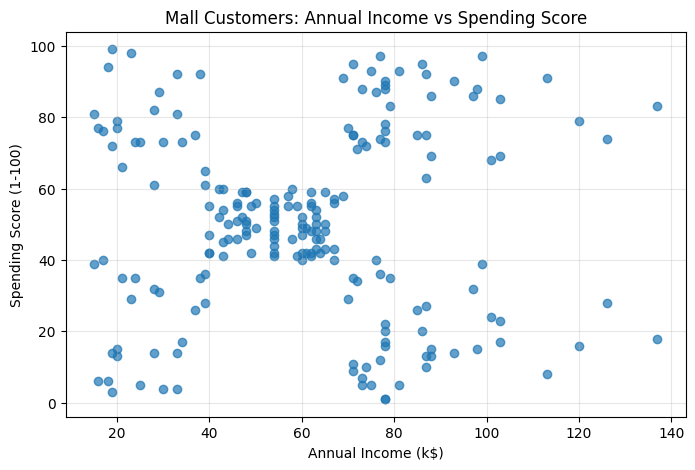

In [4]:
# Visualize Annual Income vs Spending Score

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    alpha=0.7
)

plt.title("Mall Customers: Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.grid(alpha=0.3)
plt.show()

In [5]:
# Select relevant features for clustering

X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Standardize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert standardized data into a DataFrame for easy inspection
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=["Annual Income (Standardized)", "Spending Score (Standardized)"]
)

print("Original feature shape:", X.shape)
print("Standardized feature shape:", X_scaled.shape)

print("\nFirst five standardized observations:")
display(X_scaled_df.head())

print("\nMean of standardized features:")
print(X_scaled_df.mean().round(3))

print("\nStandard deviation of standardized features:")
print(X_scaled_df.std(ddof=0).round(3))

Original feature shape: (200, 2)
Standardized feature shape: (200, 2)

First five standardized observations:


,Annual Income (Standardized),Spending Score (Standardized)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Mean of standardized features:
Annual Income (Standardized)    -0.0
Spending Score (Standardized)   -0.0
dtype: float64

Standard deviation of standardized features:
Annual Income (Standardized)     1.0
Spending Score (Standardized)    1.0
dtype: float64


k = 3, Squared Error (SSE/Inertia) = 157.7040
k = 4, Squared Error (SSE/Inertia) = 108.9213


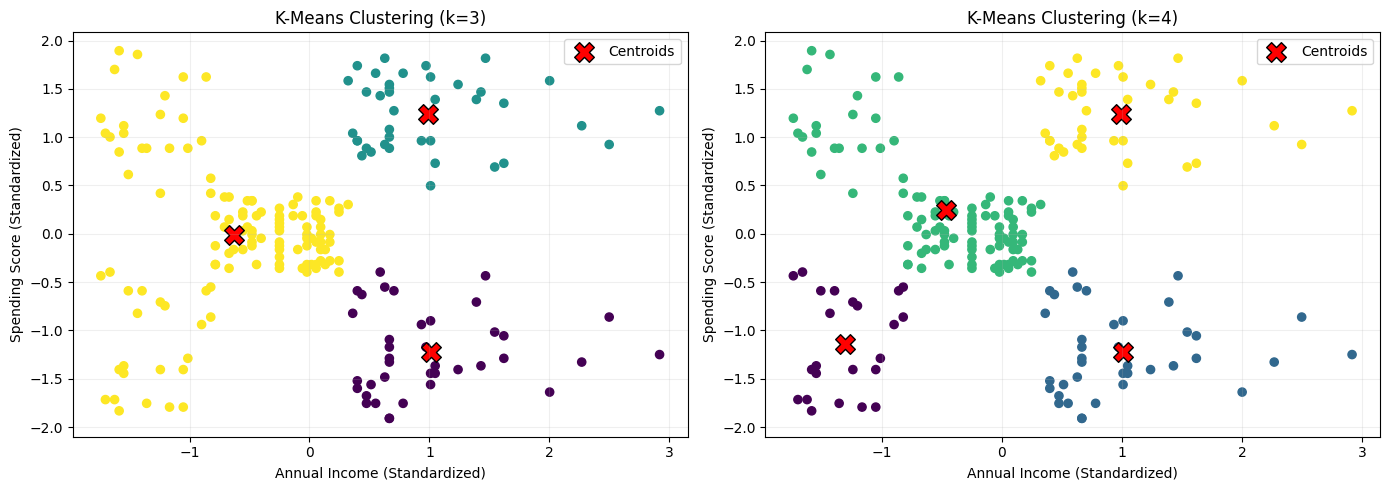

In [6]:
# K-Means clustering for k=3 and k=4

kmeans_results = {}
kmeans_sse = {}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, k in enumerate([3, 4]):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    kmeans_results[k] = model
    kmeans_sse[k] = model.inertia_

    axes[i].scatter(
        X_scaled[:, 0], X_scaled[:, 1],
        c=labels, cmap="viridis", s=35
    )
    axes[i].scatter(
        model.cluster_centers_[:, 0],
        model.cluster_centers_[:, 1],
        marker="X", s=200, c="red", edgecolor="black",
        label="Centroids"
    )
    axes[i].set_title(f"K-Means Clustering (k={k})")
    axes[i].set_xlabel("Annual Income (Standardized)")
    axes[i].set_ylabel("Spending Score (Standardized)")
    axes[i].legend()
    axes[i].grid(alpha=0.2)

    print(f"k = {k}, Squared Error (SSE/Inertia) = {model.inertia_:.4f}")

plt.tight_layout()
plt.show()

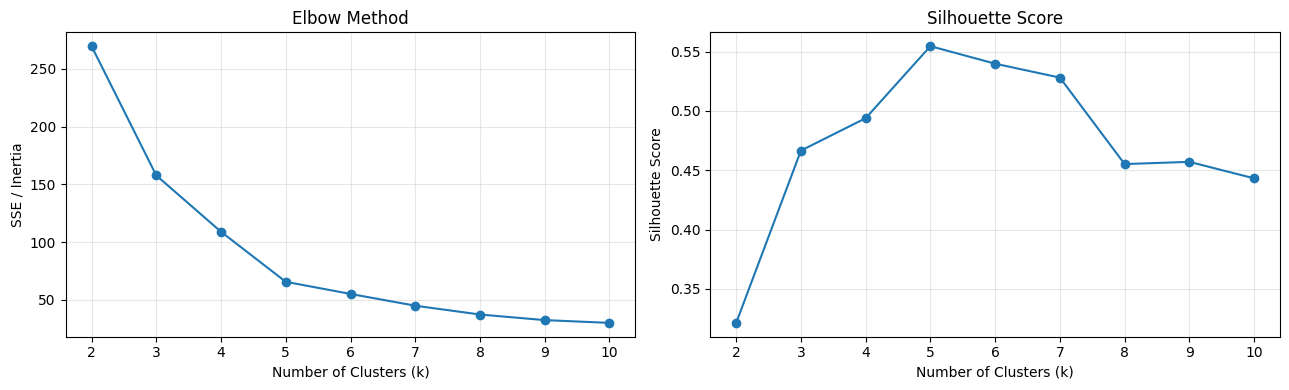

,k,SSE,Silhouette Score
0,2,269.6910,0.3213
1,3,157.7040,0.4666
2,4,108.9213,0.4939
3,5,65.5684,0.5547
4,6,55.0573,0.5399
5,7,44.8648,0.5281
6,8,37.2282,0.4552
7,9,32.3923,0.4571
8,10,29.9819,0.4432


Best k by Silhouette Score: 5


In [7]:
# Find optimal k using Elbow Method and Silhouette Score

sse_values = []
silhouette_values = []
k_range = range(2, 11)

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    sse_values.append(model.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(list(k_range), sse_values, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("SSE / Inertia")
axes[0].grid(alpha=0.3)

axes[1].plot(list(k_range), silhouette_values, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

results_kmeans = pd.DataFrame({
    "k": list(k_range),
    "SSE": sse_values,
    "Silhouette Score": silhouette_values
})

display(results_kmeans.round(4))

best_k_silhouette = list(k_range)[np.argmax(silhouette_values)]
print("Best k by Silhouette Score:", best_k_silhouette)

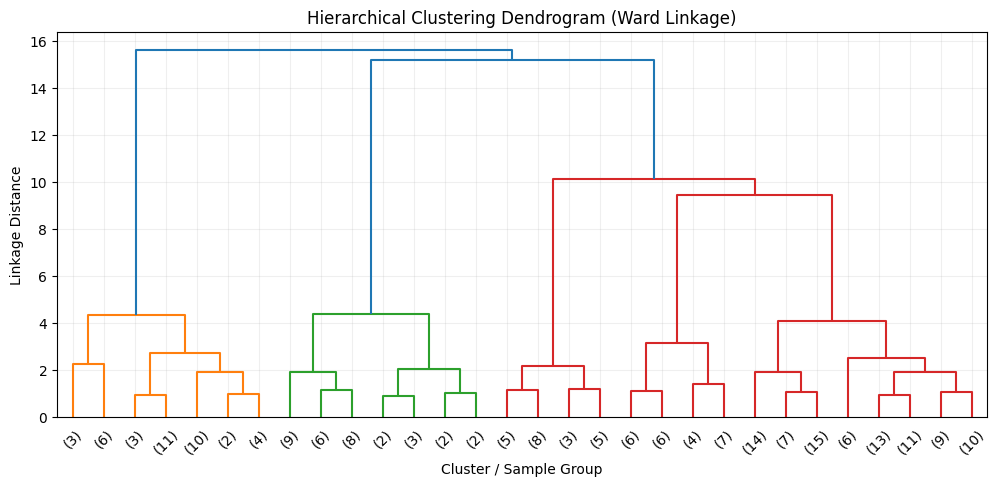

Hierarchical clustering results:


,k,Hierarchical SSE,Silhouette Score,Davies-Bouldin Index
0,2,277.9322,0.3842,0.8544
1,3,162.6221,0.4610,0.7073
2,4,111.1994,0.4926,0.6707
3,5,66.5165,0.5538,0.5779
4,6,57.0360,0.5387,0.6449
5,7,47.7560,0.5198,0.7133
6,8,39.4632,0.4309,0.7777
7,9,34.5009,0.4377,0.7765
8,10,30.8610,0.4339,0.7670


K-Means vs Hierarchical comparison:


,k,K-Means SSE,Hierarchical SSE,K-Means Silhouette,Hierarchical Silhouette,K-Means DB Index,Hierarchical DB Index
0,2,269.6910,277.9322,0.3213,0.3842,1.2670,0.8544
1,3,157.7040,162.6221,0.4666,0.4610,0.7165,0.7073
2,4,108.9213,111.1994,0.4939,0.4926,0.7096,0.6707
3,5,65.5684,66.5165,0.5547,0.5538,0.5722,0.5779
4,6,55.0573,57.0360,0.5399,0.5387,0.6546,0.6449
5,7,44.8648,47.7560,0.5281,0.5198,0.7148,0.7133
6,8,37.2282,39.4632,0.4552,0.4309,0.7602,0.7777
7,9,32.3923,34.5009,0.4571,0.4377,0.7632,0.7765
8,10,29.9819,30.8610,0.4432,0.4339,0.7935,0.7670


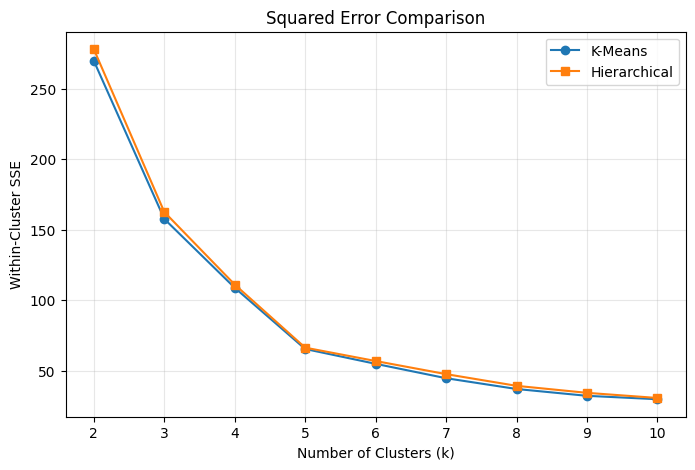

In [8]:
# Hierarchical clustering: dendrogram and evaluation

from sklearn.metrics import davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

# Create dendrogram using Ward linkage
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30)
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Cluster / Sample Group")
plt.ylabel("Linkage Distance")
plt.grid(alpha=0.2)
plt.show()

# Evaluate hierarchical clustering for different k values
hierarchical_results = []

for k in range(2, 11):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_scaled)

    # Calculate SSE from each point to its assigned cluster mean
    sse = 0
    for cluster_id in np.unique(labels):
        cluster_points = X_scaled[labels == cluster_id]
        cluster_mean = cluster_points.mean(axis=0)
        sse += np.sum((cluster_points - cluster_mean) ** 2)

    hierarchical_results.append({
        "k": k,
        "Hierarchical SSE": sse,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels)
    })

hierarchical_df = pd.DataFrame(hierarchical_results)
print("Hierarchical clustering results:")
display(hierarchical_df.round(4))

# Compare K-Means and hierarchical clustering for each k
comparison = []

for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_labels = km.fit_predict(X_scaled)

    hr = hierarchical_df[hierarchical_df["k"] == k].iloc[0]

    comparison.append({
        "k": k,
        "K-Means SSE": km.inertia_,
        "Hierarchical SSE": hr["Hierarchical SSE"],
        "K-Means Silhouette": silhouette_score(X_scaled, km_labels),
        "Hierarchical Silhouette": hr["Silhouette Score"],
        "K-Means DB Index": davies_bouldin_score(X_scaled, km_labels),
        "Hierarchical DB Index": hr["Davies-Bouldin Index"]
    })

comparison_df = pd.DataFrame(comparison)
print("K-Means vs Hierarchical comparison:")
display(comparison_df.round(4))

# Plot squared errors for both algorithms
plt.figure(figsize=(8, 5))
plt.plot(comparison_df["k"], comparison_df["K-Means SSE"],
         marker="o", label="K-Means")
plt.plot(comparison_df["k"], comparison_df["Hierarchical SSE"],
         marker="s", label="Hierarchical")
plt.title("Squared Error Comparison")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster SSE")
plt.xticks(range(2, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Result and Conclusion

K-Means and Hierarchical clustering were successfully implemented on the Mall Customer Segmentation dataset containing 200 customer records. Annual Income and Spending Score were selected as clustering features and standardized before model training.

The K-Means squared error was **157.7040 for \(k=3\)** and **108.9213 for \(k=4\)**. The Elbow Method and Silhouette Score were used to investigate the optimal number of clusters. Among the tested values of \(k=2\) to \(k=10\), the highest K-Means Silhouette Score was **0.5547 at \(k=5\)**.

Hierarchical clustering using Ward linkage was evaluated for the same cluster counts. At \(k=5\), its squared error was **66.5165**, compared with **65.5684** for K-Means. K-Means also achieved a slightly higher Silhouette Score (0.5547 versus 0.5538) and a slightly lower Davies–Bouldin Index (0.5722 versus 0.5779).

Therefore, **K-Means with five clusters is the preferred solution among the configurations tested**, although both algorithms produced similar clustering quality. The results demonstrate how clustering metrics and visualizations can help identify meaningful customer segments without predefined labels.

This practical provided experience in feature standardization, K-Means clustering, hierarchical clustering, dendrogram interpretation, squared-error calculation, and quantitative comparison of unsupervised learning algorithms.